# **Import Libraries**

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


# **Upload OTT Dataset**

In [6]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving ott_user_behavior_dataset.csv to ott_user_behavior_dataset (1).csv
Dataset uploaded successfully!


# **Load Dataset**

In [7]:

file_name = "ott_user_behavior_dataset.csv"
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (150, 7)


,User_ID,Viewing_History,Session_Duration,Content_Genre,Subscription_Plan,Inactivity_Period,Retention_Status
0,OTT0074,"13 sessions | Documentary, Sports, Drama, Anim...",28.92,Sports,Standard,11,At Risk
1,OTT0019,"31 sessions | Sci-Fi, Thriller, Animation, Spo...",101.44,Sports,Premium,3,Retained
2,OTT0119,"17 sessions | Action, Drama, Romance, Thriller",54.74,Romance,Basic,28,Churned
3,OTT0079,32 sessions | Action,110.42,Action,Basic,4,At Risk
4,OTT0077,"20 sessions | Comedy, Sci-Fi",39.13,Sci-Fi,Basic,5,Retained


# **Dataset Information**

In [8]:

print("Dataset Information:")
print("=" * 50)

df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   User_ID            150 non-null    object 
 1   Viewing_History    150 non-null    object 
 2   Session_Duration   150 non-null    float64
 3   Content_Genre      150 non-null    object 
 4   Subscription_Plan  150 non-null    object 
 5   Inactivity_Period  150 non-null    int64  
 6   Retention_Status   150 non-null    object 
dtypes: float64(1), int64(1), object(5)
memory usage: 8.3+ KB


In [9]:
# Check Missing Values

print("Missing Values in Each Column:")
print("=" * 50)

missing_values = df.isnull().sum()

print(missing_values)

if missing_values.sum() == 0:
    print("\nNo missing values found.")
else:
    print("\nMissing values are present.")

Missing Values in Each Column:
User_ID              0
Viewing_History      0
Session_Duration     0
Content_Genre        0
Subscription_Plan    0
Inactivity_Period    0
Retention_Status     0
dtype: int64

No missing values found.


In [10]:
# Check Duplicate Records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate records found.")
else:
    print("Duplicate records found.")

Number of duplicate records: 0
No duplicate records found.


In [11]:
# Check Duplicate User IDs

duplicate_users = df["User_ID"].duplicated().sum()

print("Duplicate User IDs:", duplicate_users)

if duplicate_users == 0:
    print("All User IDs are unique.")
else:
    print("Duplicate User IDs found.")

Duplicate User IDs: 0
All User IDs are unique.


In [13]:
# Display Dataset Columns

print("Columns in the dataset:")
print("=" * 50)

for column in df.columns:
    print(column)

Columns in the dataset:
User_ID
Viewing_History
Session_Duration
Content_Genre
Subscription_Plan
Inactivity_Period
Retention_Status


In [14]:
#  Descriptive Statistics

print("Descriptive Statistics")
print("=" * 50)

display(df.describe())

Descriptive Statistics


,Session_Duration,Inactivity_Period
count,150.000000,150.000000
mean,77.928333,9.660000
std,40.395477,12.213333
min,5.520000,0.000000
25%,44.447500,2.000000
50%,77.825000,4.000000
75%,106.457500,12.000000
max,172.810000,57.000000


In [16]:
#  Check Categorical Values

print("Subscription Plans:")
print(df["Subscription_Plan"].unique())

print("\nContent Genres:")
print(df["Content_Genre"].unique())

print("\nRetention Status:")
print(df["Retention_Status"].unique())

Subscription Plans:
['Standard' 'Premium' 'Basic']

Content Genres:
['Sports' 'Romance' 'Action' 'Sci-Fi' 'Drama' 'Horror' 'Documentary'
 'Animation' 'Comedy' 'Thriller']

Retention Status:
['At Risk' 'Retained' 'Churned']


In [17]:
#  Clean Numerical Columns

df["Session_Duration"] = pd.to_numeric(
    df["Session_Duration"],
    errors="coerce"
)

df["Inactivity_Period"] = pd.to_numeric(
    df["Inactivity_Period"],
    errors="coerce"
)

# Remove invalid values
df = df[
    (df["Session_Duration"] > 0) &
    (df["Inactivity_Period"] >= 0)
].copy()

print("Numerical data cleaned successfully.")
print("Current dataset shape:", df.shape)

Numerical data cleaned successfully.
Current dataset shape: (150, 7)


In [18]:
#  Extract Viewing Count

df["Viewing_Count"] = (
    df["Viewing_History"]
    .str.extract(r"(\d+)")
    .astype(int)
)

print("Viewing_Count created successfully.")

display(
    df[
        [
            "User_ID",
            "Viewing_History",
            "Viewing_Count"
        ]
    ].head(10)
)

Viewing_Count created successfully.


,User_ID,Viewing_History,Viewing_Count
0,OTT0074,"13 sessions | Documentary, Sports, Drama, Anim...",13
1,OTT0019,"31 sessions | Sci-Fi, Thriller, Animation, Spo...",31
2,OTT0119,"17 sessions | Action, Drama, Romance, Thriller",17
3,OTT0079,32 sessions | Action,32
4,OTT0077,"20 sessions | Comedy, Sci-Fi",20
5,OTT0032,"41 sessions | Drama, Thriller",41
6,OTT0065,"36 sessions | Romance, Action, Sci-Fi, Drama, ...",36
7,OTT0142,"30 sessions | Sports, Thriller, Animation, Sci-Fi",30
8,OTT0069,"79 sessions | Horror, Thriller, Sci-Fi",79
9,OTT0083,"37 sessions | Documentary, Sci-Fi",37


In [19]:
# Calculate Content Diversity

def calculate_diversity(history):
    try:
        genres = history.split("|")[1]
        genres = [g.strip() for g in genres.split(",")]
        return len(set(genres))
    except:
        return 0

df["Content_Diversity"] = df["Viewing_History"].apply(
    calculate_diversity
)

print("Content Diversity calculated successfully.")

display(
    df[
        [
            "User_ID",
            "Viewing_History",
            "Content_Diversity"
        ]
    ].head(10)
)

Content Diversity calculated successfully.


,User_ID,Viewing_History,Content_Diversity
0,OTT0074,"13 sessions | Documentary, Sports, Drama, Anim...",5
1,OTT0019,"31 sessions | Sci-Fi, Thriller, Animation, Spo...",5
2,OTT0119,"17 sessions | Action, Drama, Romance, Thriller",4
3,OTT0079,32 sessions | Action,1
4,OTT0077,"20 sessions | Comedy, Sci-Fi",2
5,OTT0032,"41 sessions | Drama, Thriller",2
6,OTT0065,"36 sessions | Romance, Action, Sci-Fi, Drama, ...",5
7,OTT0142,"30 sessions | Sports, Thriller, Animation, Sci-Fi",4
8,OTT0069,"79 sessions | Horror, Thriller, Sci-Fi",3
9,OTT0083,"37 sessions | Documentary, Sci-Fi",2


In [20]:
#  Create Engagement Score

df["Engagement_Score"] = (
    df["Session_Duration"] * 0.4
    + df["Viewing_Count"] * 1.5
    + df["Content_Diversity"] * 5
    - df["Inactivity_Period"] * 1.2
)

print("Engagement Score created successfully.")

display(
    df[
        [
            "User_ID",
            "Session_Duration",
            "Viewing_Count",
            "Content_Diversity",
            "Inactivity_Period",
            "Engagement_Score"
        ]
    ].head(10)
)

Engagement Score created successfully.


,User_ID,Session_Duration,Viewing_Count,Content_Diversity,Inactivity_Period,Engagement_Score
0,OTT0074,28.92,13,5,11,42.868
1,OTT0019,101.44,31,5,3,108.476
2,OTT0119,54.74,17,4,28,33.796
3,OTT0079,110.42,32,1,4,92.368
4,OTT0077,39.13,20,2,5,49.652
5,OTT0032,136.69,41,2,0,126.176
6,OTT0065,98.64,36,5,4,113.656
7,OTT0142,80.94,30,4,1,96.176
8,OTT0069,140.60,79,3,0,189.740
9,OTT0083,94.47,37,2,7,94.888


In [21]:
# Identify Viewing Behaviour Patterns

def classify_behavior(score):
    if score >= 80:
        return "Highly Engaged"
    elif score >= 50:
        return "Regular"
    elif score >= 30:
        return "Casual"
    elif score >= 10:
        return "Declining"
    else:
        return "Inactive"

df["Behaviour_Segment"] = df["Engagement_Score"].apply(
    classify_behavior
)

print("Behaviour segments created successfully.")

display(
    df[
        [
            "User_ID",
            "Engagement_Score",
            "Behaviour_Segment"
        ]
    ].head(10)
)

Behaviour segments created successfully.


,User_ID,Engagement_Score,Behaviour_Segment
0,OTT0074,42.868,Casual
1,OTT0019,108.476,Highly Engaged
2,OTT0119,33.796,Casual
3,OTT0079,92.368,Highly Engaged
4,OTT0077,49.652,Casual
5,OTT0032,126.176,Highly Engaged
6,OTT0065,113.656,Highly Engaged
7,OTT0142,96.176,Highly Engaged
8,OTT0069,189.740,Highly Engaged
9,OTT0083,94.888,Highly Engaged


In [22]:
#  Behaviour Segment Distribution

print("Number of Users in Each Behaviour Segment:")
print("=" * 50)

print(
    df["Behaviour_Segment"].value_counts()
)

Number of Users in Each Behaviour Segment:
Behaviour_Segment
Highly Engaged    80
Regular           23
Casual            22
Inactive          17
Declining          8
Name: count, dtype: int64


In [23]:
# Average Watch Time by Customer Segment

average_watch_time = (
    df.groupby("Behaviour_Segment")["Session_Duration"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Watch Time by Customer Segment:")
print("=" * 50)

display(
    average_watch_time.round(2).to_frame(
        "Average Session Duration"
    )
)

Average Watch Time by Customer Segment:


,Average Session Duration
Behaviour_Segment,
Highly Engaged,107.56
Regular,63.49
Casual,45.16
Declining,28.48
Inactive,23.69


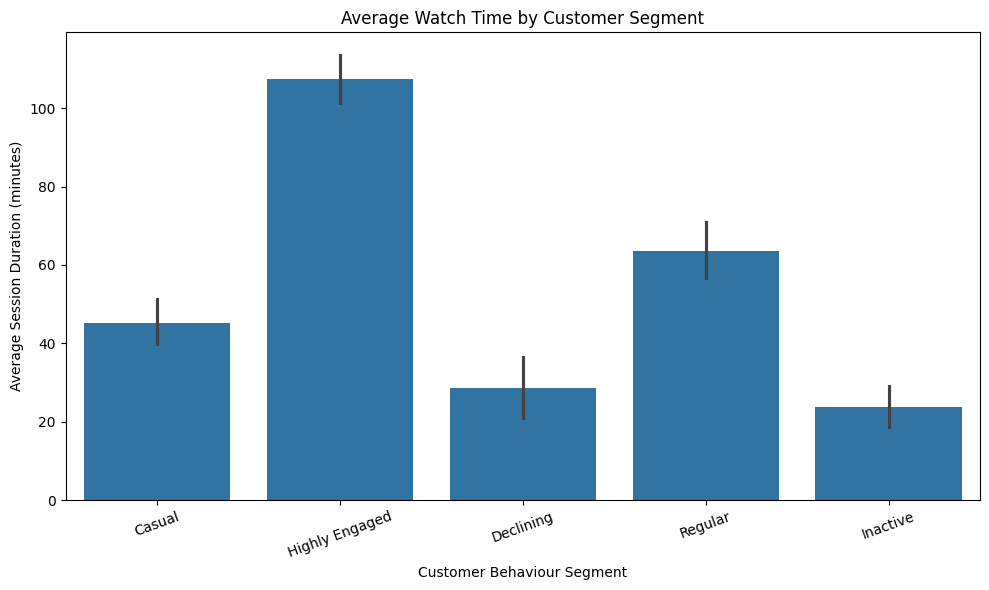

In [24]:
#  Average Session Duration by Behaviour Segment

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Behaviour_Segment",
    y="Session_Duration",
    estimator=np.mean
)

plt.title("Average Watch Time by Customer Segment")
plt.xlabel("Customer Behaviour Segment")
plt.ylabel("Average Session Duration (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [26]:
# Retention Status Analysis

retention_counts = df["Retention_Status"].value_counts()

print("Retention Status:")
print("=" * 50)

print(retention_counts)

Retention Status:
Retention_Status
Retained    89
At Risk     31
Churned     30
Name: count, dtype: int64


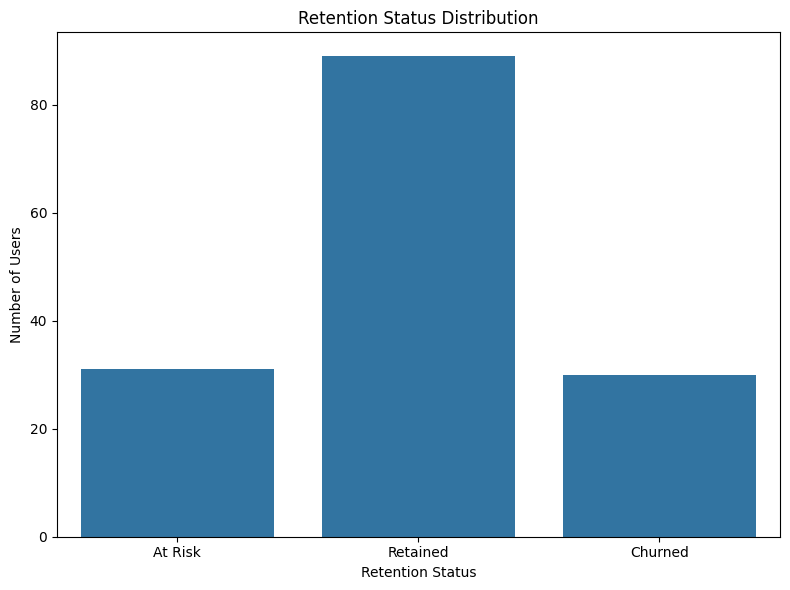

In [27]:
#  Retention Status Distribution

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Retention_Status"
)

plt.title("Retention Status Distribution")
plt.xlabel("Retention Status")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

In [28]:
#  Content Diversity Analysis

diversity_analysis = (
    df.groupby("Content_Diversity")
    .agg(
        Average_Session_Duration=("Session_Duration", "mean"),
        Average_Engagement=("Engagement_Score", "mean"),
        Users=("User_ID", "count")
    )
    .reset_index()
)

display(diversity_analysis.round(2))

,Content_Diversity,Average_Session_Duration,Average_Engagement,Users
0,1,72.71,61.27,28
1,2,102.56,108.07,30
2,3,63.22,67.05,30
3,4,74.67,84.42,26
4,5,76.08,85.82,36


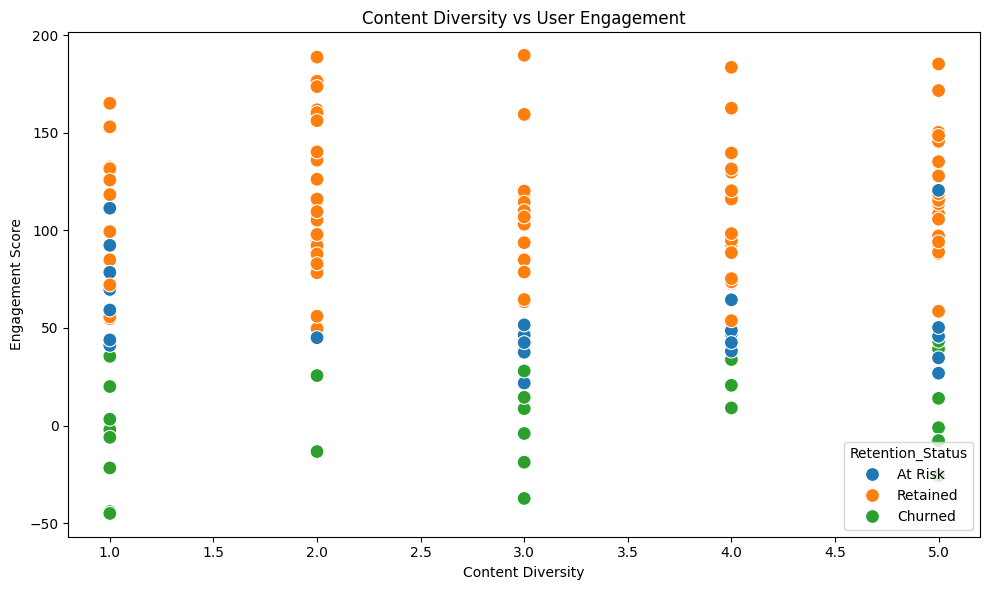

In [29]:
#  Content Diversity vs Engagement

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Content_Diversity",
    y="Engagement_Score",
    hue="Retention_Status",
    s=100
)

plt.title("Content Diversity vs User Engagement")
plt.xlabel("Content Diversity")
plt.ylabel("Engagement Score")

plt.tight_layout()
plt.show()

In [31]:
#  Subscription Plan Analysis

subscription_analysis = (
    df.groupby("Subscription_Plan")
    .agg(
        Users=("User_ID", "count"),
        Average_Session=("Session_Duration", "mean"),
        Average_Inactivity=("Inactivity_Period", "mean"),
        Average_Engagement=("Engagement_Score", "mean")
    )
    .reset_index()
)

display(
    subscription_analysis.round(2)
)

,Subscription_Plan,Users,Average_Session,Average_Inactivity,Average_Engagement
0,Basic,47,56.30,13.11,58.10
1,Premium,48,98.12,6.75,104.99
2,Standard,55,78.79,9.25,81.51


In [32]:
#  Retention Rate by Subscription Plan

retention_rate = (
    df.assign(
        Retained=df["Retention_Status"] == "Retained"
    )
    .groupby("Subscription_Plan")["Retained"]
    .mean()
    * 100
)

print("Retention Rate by Subscription Plan:")
print("=" * 50)

display(
    retention_rate.round(2).to_frame(
        "Retention Rate (%)"
    )
)

Retention Rate by Subscription Plan:


,Retention Rate (%)
Subscription_Plan,
Basic,38.30
Premium,77.08
Standard,61.82


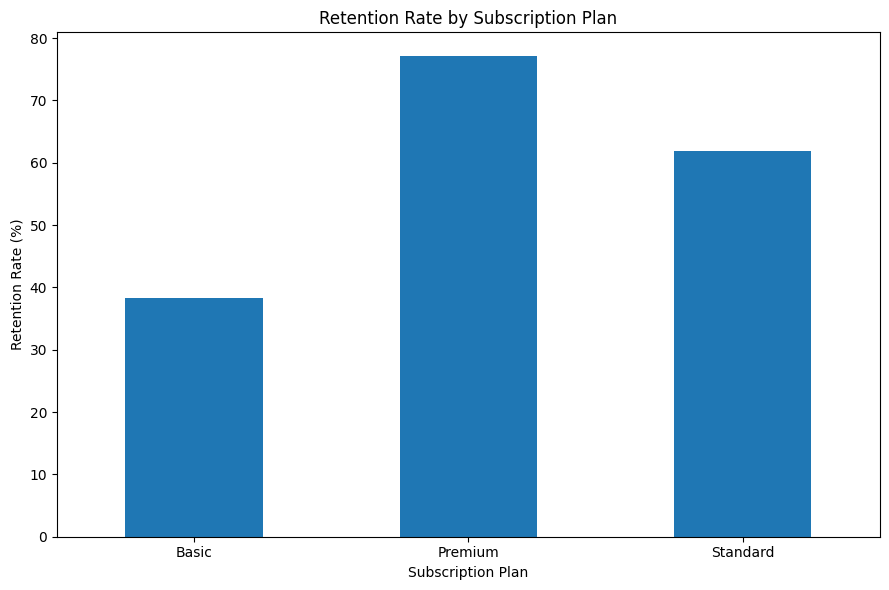

In [33]:
# Subscription Plan vs Retention Rate

plt.figure(figsize=(9, 6))

retention_rate.plot(
    kind="bar"
)

plt.title("Retention Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [34]:
#  Identify Users at Risk of Declining Engagement

at_risk_users = df[
    (df["Inactivity_Period"] >= 15) |
    (df["Session_Duration"] < 40) |
    (df["Viewing_Count"] < 10)
].copy()

print("Users showing early signs of declining engagement:")
print("=" * 60)

print("Number of at-risk users:", len(at_risk_users))

display(
    at_risk_users[
        [
            "User_ID",
            "Session_Duration",
            "Viewing_Count",
            "Content_Diversity",
            "Inactivity_Period",
            "Retention_Status"
        ]
    ].head(20)
)

Users showing early signs of declining engagement:
Number of at-risk users: 42


,User_ID,Session_Duration,Viewing_Count,Content_Diversity,Inactivity_Period,Retention_Status
0,OTT0074,28.92,13,5,11,At Risk
2,OTT0119,54.74,17,4,28,Churned
4,OTT0077,39.13,20,2,5,Retained
11,OTT0013,42.41,14,3,26,At Risk
16,OTT0105,31.77,9,5,10,Churned
17,OTT0070,25.03,7,3,33,Churned
18,OTT0056,23.58,2,3,54,Churned
21,OTT0128,42.14,8,1,30,Churned
28,OTT0046,83.67,10,1,15,Churned
29,OTT0031,22.97,10,5,5,Churned


In [35]:
#  Declining Engagement Summary

declining_summary = (
    at_risk_users.groupby("Retention_Status")
    .size()
    .reset_index(name="Users")
)

print("At-Risk User Summary:")
print("=" * 50)

display(declining_summary)

At-Risk User Summary:


,Retention_Status,Users
0,At Risk,12
1,Churned,29
2,Retained,1


In [36]:
#  Prepare Features for Random Forest

model_df = df[
    [
        "Session_Duration",
        "Viewing_Count",
        "Content_Diversity",
        "Inactivity_Period",
        "Subscription_Plan",
        "Content_Genre",
        "Retention_Status"
    ]
].copy()

# Encode categorical features
model_df = pd.get_dummies(
    model_df,
    columns=[
        "Subscription_Plan",
        "Content_Genre"
    ],
    drop_first=True
)

print("Data prepared for Random Forest.")

display(model_df.head())

Data prepared for Random Forest.


,Session_Duration,Viewing_Count,Content_Diversity,Inactivity_Period,Retention_Status,Subscription_Plan_Premium,Subscription_Plan_Standard,Content_Genre_Animation,Content_Genre_Comedy,Content_Genre_Documentary,Content_Genre_Drama,Content_Genre_Horror,Content_Genre_Romance,Content_Genre_Sci-Fi,Content_Genre_Sports,Content_Genre_Thriller
0,28.92,13,5,11,At Risk,False,True,False,False,False,False,False,False,False,True,False
1,101.44,31,5,3,Retained,True,False,False,False,False,False,False,False,False,True,False
2,54.74,17,4,28,Churned,False,False,False,False,False,False,False,True,False,False,False
3,110.42,32,1,4,At Risk,False,False,False,False,False,False,False,False,False,False,False
4,39.13,20,2,5,Retained,False,False,False,False,False,False,False,False,True,False,False


In [37]:
#  Separate Features and Target

X = model_df.drop(
    "Retention_Status",
    axis=1
)

y = model_df["Retention_Status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (150, 15)
Target shape: (150,)

Target classes:
Retention_Status
Retained    89
At Risk     31
Churned     30
Name: count, dtype: int64


In [38]:
#  Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 15)
Testing data: (30, 15)


In [39]:
#  Train Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10,
    min_samples_split=4
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [40]:
#  Make Predictions

y_pred = rf_model.predict(X_test)

print("Predictions generated successfully.")

print("\nPredicted values:")
print(y_pred)

Predictions generated successfully.

Predicted values:
['Retained' 'Churned' 'Retained' 'Churned' 'Retained' 'Retained'
 'Retained' 'Churned' 'Retained' 'Retained' 'Retained' 'Churned' 'At Risk'
 'Retained' 'Retained' 'At Risk' 'Retained' 'Churned' 'Retained' 'At Risk'
 'Churned' 'Retained' 'Retained' 'Retained' 'Retained' 'Retained'
 'Retained' 'Retained' 'Retained' 'Retained']


In [41]:
# Model Accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Random Forest Accuracy:")
print(f"{accuracy * 100:.2f}%")

Random Forest Accuracy:
90.00%


In [42]:
# Model Evaluation Metrics

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Model Evaluation")
print("=" * 50)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

Model Evaluation
Accuracy  : 90.00%
Precision : 91.43%
Recall    : 90.00%
F1 Score  : 88.72%


In [43]:
#  Classification Report

print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Classification Report
              precision    recall  f1-score   support

     At Risk       1.00      0.50      0.67         6
     Churned       1.00      1.00      1.00         6
    Retained       0.86      1.00      0.92        18

    accuracy                           0.90        30
   macro avg       0.95      0.83      0.86        30
weighted avg       0.91      0.90      0.89        30



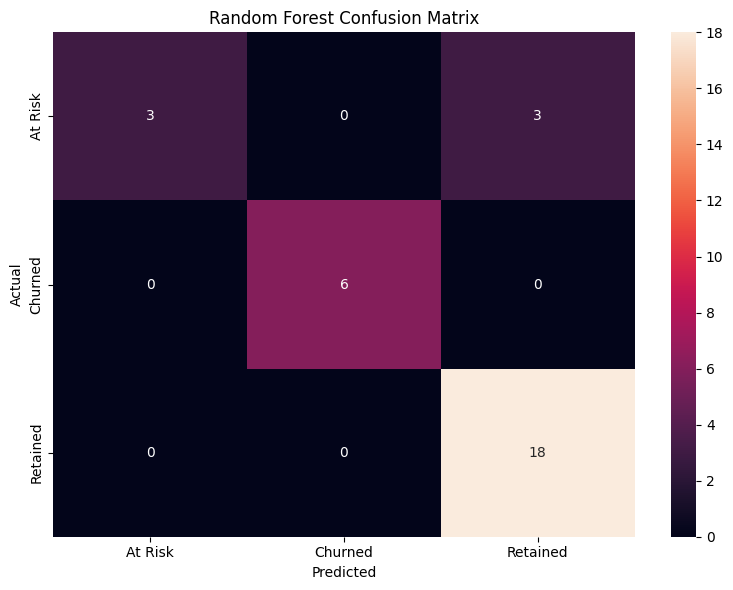

In [44]:
#  Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [45]:
#  Random Forest Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,Session_Duration,0.295798
1,Viewing_Count,0.264433
3,Inactivity_Period,0.262672
2,Content_Diversity,0.046363
4,Subscription_Plan_Premium,0.030170
9,Content_Genre_Drama,0.014447
5,Subscription_Plan_Standard,0.012766
12,Content_Genre_Sci-Fi,0.012079
10,Content_Genre_Horror,0.011619
8,Content_Genre_Documentary,0.011229


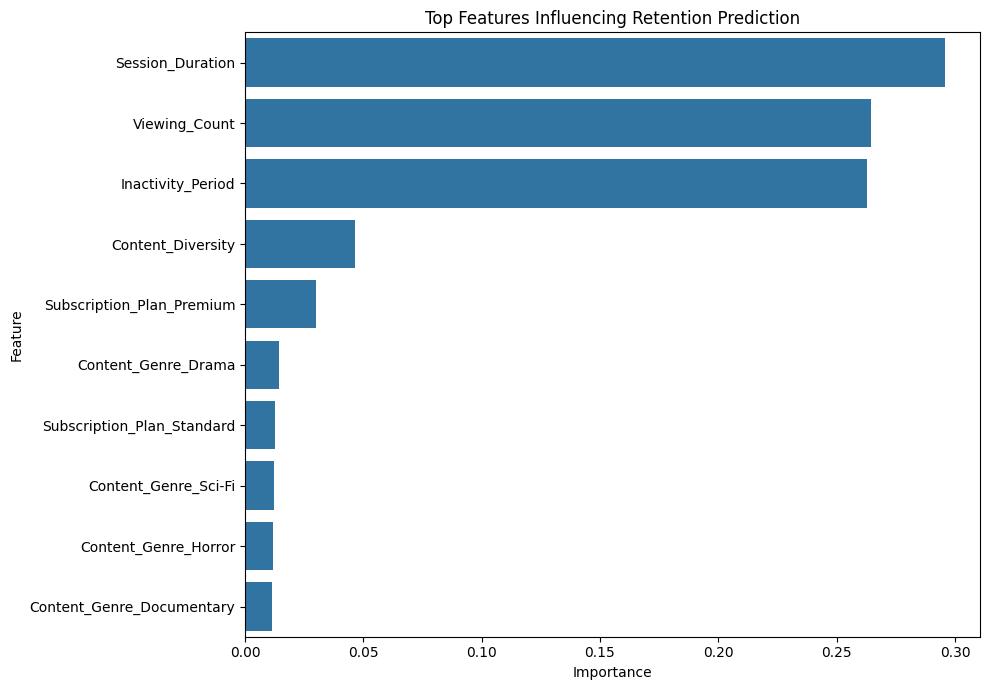

In [47]:
# Feature Importance Plot

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top Features Influencing Retention Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [48]:
#  Generate Key Insights

highest_watch_segment = (
    df.groupby("Behaviour_Segment")["Session_Duration"]
    .mean()
    .idxmax()
)

highest_watch_time = (
    df.groupby("Behaviour_Segment")["Session_Duration"]
    .mean()
    .max()
)

highest_inactivity_status = (
    df.groupby("Retention_Status")["Inactivity_Period"]
    .mean()
    .idxmax()
)

best_subscription = retention_rate.idxmax()
best_retention_rate = retention_rate.max()

most_important_feature = feature_importance.iloc[0]["Feature"]

average_session = df["Session_Duration"].mean()
average_inactivity = df["Inactivity_Period"].mean()

print("KEY INSIGHTS")
print("=" * 70)

print(f"1. {highest_watch_segment} users have the highest average watch time "
      f"at approximately {highest_watch_time:.2f} minutes.")

print(f"2. The overall average session duration is "
      f"{average_session:.2f} minutes.")

print(f"3. Users classified as '{highest_inactivity_status}' have the "
      f"highest average inactivity period.")

print(f"4. {best_subscription} has the highest observed retention rate "
      f"at {best_retention_rate:.2f}%.")

print(f"5. The average inactivity period across users is "
      f"{average_inactivity:.2f} days.")

print(f"6. The Random Forest model identifies "
      f"'{most_important_feature}' as the most influential feature "
      f"among the model inputs.")

print(f"7. {len(at_risk_users)} users show at least one early warning "
      f"sign of declining engagement.")

KEY INSIGHTS
1. Highly Engaged users have the highest average watch time at approximately 107.56 minutes.
2. The overall average session duration is 77.93 minutes.
3. Users classified as 'Churned' have the highest average inactivity period.
4. Premium has the highest observed retention rate at 77.08%.
5. The average inactivity period across users is 9.66 days.
6. The Random Forest model identifies 'Session_Duration' as the most influential feature among the model inputs.
7. 42 users show at least one early warning sign of declining engagement.


In [49]:
# OTT Engagement Action Plan

print("PRACTICAL ACTION PLAN")
print("=" * 70)

print("""
1. PERSONALIZED RECOMMENDATIONS
   Recommend content based on each user's viewing history and preferred genres.

2. RE-ENGAGEMENT CAMPAIGNS
   Send personalized notifications to users who have remained inactive
   for a long period.

3. CONTENT DIVERSIFICATION
   Recommend different genres to users with very low content diversity
   to encourage broader content discovery.

4. EARLY WARNING SYSTEM
   Monitor session duration, viewing frequency and inactivity.
   Users showing declining activity can be targeted before they churn.

5. SUBSCRIPTION STRATEGY
   Compare engagement and retention across subscription plans and
   provide suitable upgrades, offers or personalized plans.

6. PERSONALIZED CONTENT FEEDS
   Highly engaged users can receive new-release recommendations,
   while declining users can receive highly relevant short-form
   or popular content.

7. CONTINUOUS MONITORING
   Periodically retrain the Random Forest model using new viewing
   behaviour data to improve retention prediction.
""")

PRACTICAL ACTION PLAN

1. PERSONALIZED RECOMMENDATIONS
   Recommend content based on each user's viewing history and preferred genres.

2. RE-ENGAGEMENT CAMPAIGNS
   Send personalized notifications to users who have remained inactive
   for a long period.

3. CONTENT DIVERSIFICATION
   Recommend different genres to users with very low content diversity
   to encourage broader content discovery.

4. EARLY WARNING SYSTEM
   Monitor session duration, viewing frequency and inactivity.
   Users showing declining activity can be targeted before they churn.

5. SUBSCRIPTION STRATEGY
   Compare engagement and retention across subscription plans and
   provide suitable upgrades, offers or personalized plans.

6. PERSONALIZED CONTENT FEEDS
   Highly engaged users can receive new-release recommendations,
   while declining users can receive highly relevant short-form
   or popular content.

7. CONTINUOUS MONITORING
   Periodically retrain the Random Forest model using new viewing
   behaviour dat

                 OTT USER BEHAVIOUR DASHBOARD

KEY METRICS
--------------------------------------------------------------------------------
Total Users              : 150
Average Watch Time       : 77.93 minutes
Average Inactivity       : 9.66 days
Retention Rate           : 59.33%
Users At Risk            : 42

BEHAVIOUR SEGMENTS
--------------------------------------------------------------------------------
Behaviour_Segment
Highly Engaged    80
Regular           23
Casual            22
Inactive          17
Declining          8
Name: count, dtype: int64

SUBSCRIPTION PLAN ANALYSIS
--------------------------------------------------------------------------------


,Users,Avg_Watch_Time,Avg_Inactivity
Subscription_Plan,,,
Basic,47,56.30,13.11
Premium,48,98.12,6.75
Standard,55,78.79,9.25


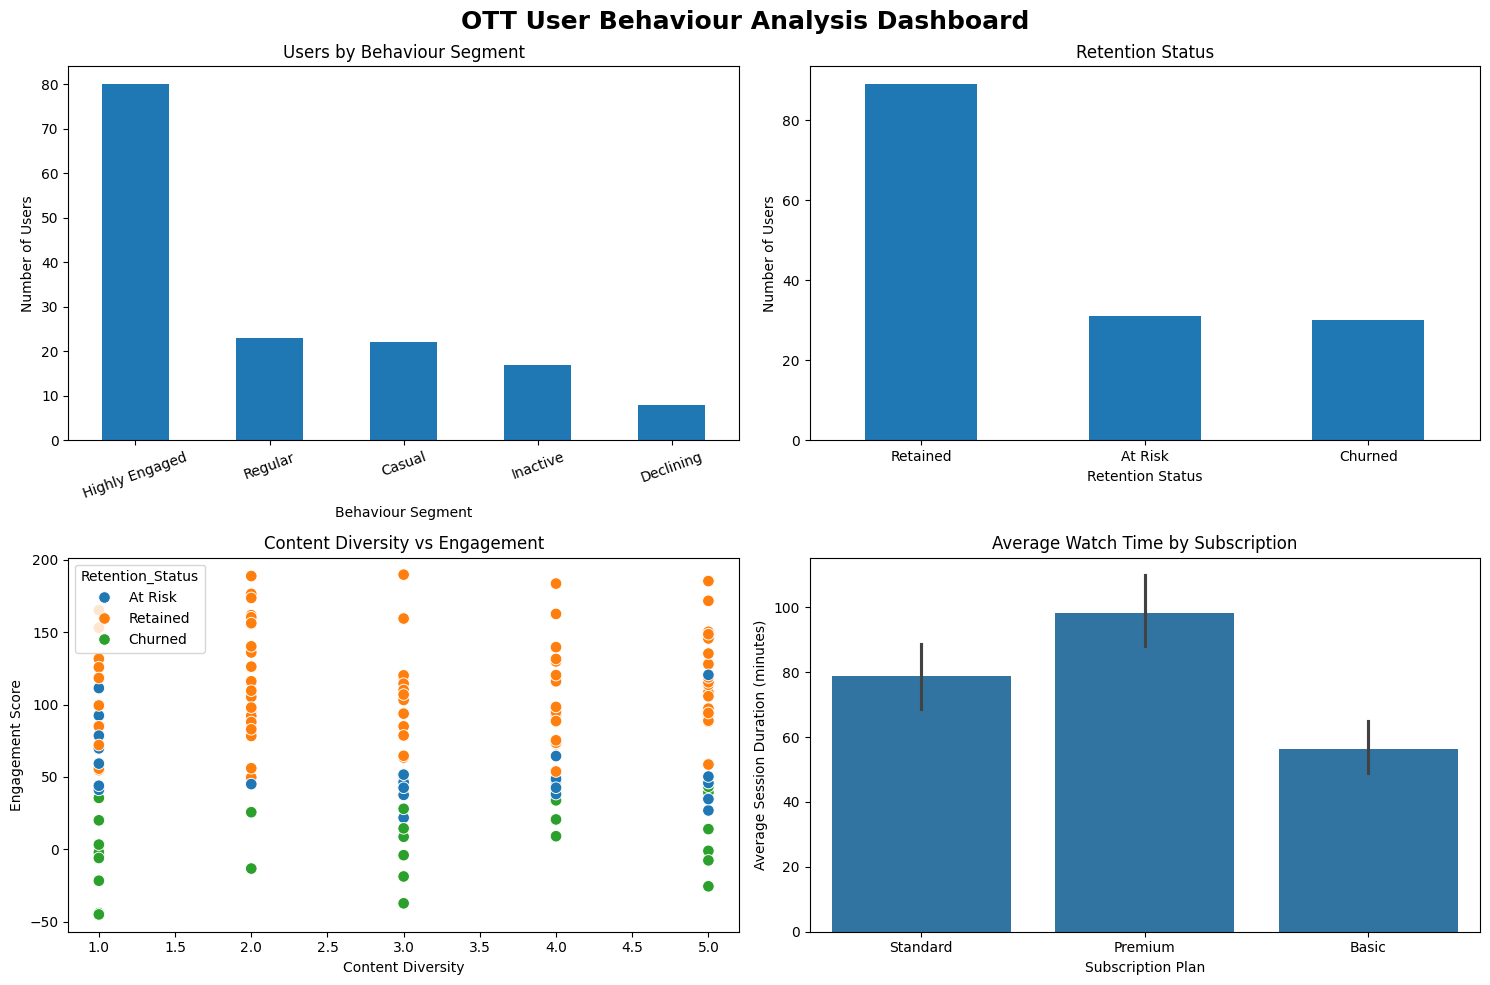

In [51]:
# ============================================================
# SIMPLE OTT USER BEHAVIOUR DASHBOARD
# Uses data from previous cells
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Calculate dashboard values
# ------------------------------------------------------------

total_users = len(df)

avg_watch_time = df["Session_Duration"].mean()

avg_inactivity = df["Inactivity_Period"].mean()

retained_users = (df["Retention_Status"] == "Retained").sum()

retention_rate = (retained_users / total_users) * 100

at_risk_users = len(
    df[
        (df["Inactivity_Period"] >= 15) |
        (df["Session_Duration"] < 40) |
        (df["Viewing_Count"] < 10)
    ]
)

# ------------------------------------------------------------
# 2. Dashboard Title
# ------------------------------------------------------------

print("=" * 80)
print("                 OTT USER BEHAVIOUR DASHBOARD")
print("=" * 80)

# ------------------------------------------------------------
# 3. Key Metrics
# ------------------------------------------------------------

print("\nKEY METRICS")
print("-" * 80)

print(f"Total Users              : {total_users}")
print(f"Average Watch Time       : {avg_watch_time:.2f} minutes")
print(f"Average Inactivity       : {avg_inactivity:.2f} days")
print(f"Retention Rate           : {retention_rate:.2f}%")
print(f"Users At Risk            : {at_risk_users}")

# ------------------------------------------------------------
# 4. Behaviour Segment
# ------------------------------------------------------------

print("\nBEHAVIOUR SEGMENTS")
print("-" * 80)

behavior_counts = df["Behaviour_Segment"].value_counts()

print(behavior_counts)

# ------------------------------------------------------------
# 5. Subscription Analysis
# ------------------------------------------------------------

print("\nSUBSCRIPTION PLAN ANALYSIS")
print("-" * 80)

subscription_summary = df.groupby("Subscription_Plan").agg(
    Users=("User_ID", "count"),
    Avg_Watch_Time=("Session_Duration", "mean"),
    Avg_Inactivity=("Inactivity_Period", "mean")
).round(2)

display(subscription_summary)

# ------------------------------------------------------------
# 6. Create Dashboard Charts
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ------------------------------------------------------------
# Chart 1: Behaviour Segments
# ------------------------------------------------------------

behavior_counts.plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Users by Behaviour Segment")
axes[0, 0].set_xlabel("Behaviour Segment")
axes[0, 0].set_ylabel("Number of Users")
axes[0, 0].tick_params(axis="x", rotation=20)

# ------------------------------------------------------------
# Chart 2: Retention Status
# ------------------------------------------------------------

retention_counts = df["Retention_Status"].value_counts()

retention_counts.plot(
    kind="bar",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Retention Status")
axes[0, 1].set_xlabel("Retention Status")
axes[0, 1].set_ylabel("Number of Users")
axes[0, 1].tick_params(axis="x", rotation=0)

# ------------------------------------------------------------
# Chart 3: Content Diversity vs Engagement
# ------------------------------------------------------------

sns.scatterplot(
    data=df,
    x="Content_Diversity",
    y="Engagement_Score",
    hue="Retention_Status",
    ax=axes[1, 0],
    s=70
)

axes[1, 0].set_title(
    "Content Diversity vs Engagement"
)

axes[1, 0].set_xlabel("Content Diversity")
axes[1, 0].set_ylabel("Engagement Score")

# ------------------------------------------------------------
# Chart 4: Subscription Plan vs Watch Time
# ------------------------------------------------------------

sns.barplot(
    data=df,
    x="Subscription_Plan",
    y="Session_Duration",
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Average Watch Time by Subscription"
)

axes[1, 1].set_xlabel("Subscription Plan")
axes[1, 1].set_ylabel(
    "Average Session Duration (minutes)"
)

# ------------------------------------------------------------
# Dashboard Layout
# ------------------------------------------------------------

plt.suptitle(
    "OTT User Behaviour Analysis Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.show()